In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare
from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
SEARCH_SPACE = {
    "minimum_loss": [0.5, 0.75, 1.0],
}

In [ ]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Experiment": {"minimum_loss": 1.0}
}

In [5]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True).dropna(axis=1)
df_prices

,BTC,ETH,XRP,USDT,BCH,LTC,EOS,BNB,BSV,XLM,...,MKR,ONT,DOGE,VET,BAT,OMG,SNX,ZRX,ICX,QTUM
Date,,,,,,,,,,,,,,,,,,,,,
2020-02-13,10214.379883,268.099243,0.326706,0.998579,474.317993,80.403427,5.341575,25.440100,359.041138,0.082655,...,625.763184,1.021036,0.003026,0.008026,0.295389,1.280141,0.932967,0.320865,0.394342,2.842507
2020-02-14,10312.116211,284.217499,0.334822,1.000114,491.160645,82.990349,5.361947,26.296959,360.390015,0.085796,...,638.993713,1.071109,0.003130,0.008323,0.311020,1.370907,0.992797,0.345264,0.400229,3.015611
2020-02-15,9889.424805,264.728577,0.306236,0.999128,437.664948,76.513245,4.743118,24.149651,310.077820,0.079246,...,607.280212,0.957589,0.002920,0.007440,0.280342,1.289413,0.949770,0.317226,0.360399,2.677241
2020-02-16,9934.433594,259.894714,0.295034,0.999272,415.940643,75.152588,4.412250,23.466389,285.867523,0.075079,...,634.711975,0.909603,0.002774,0.007133,0.264260,1.190897,0.945258,0.299002,0.348740,2.511193
2020-02-17,9690.142578,266.363434,0.286572,0.998474,409.344574,73.251305,4.346360,23.551378,309.441620,0.071851,...,614.943604,0.878514,0.002712,0.006756,0.266563,1.169630,1.011205,0.291352,0.344687,2.499368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-31,68233.312500,2104.708252,1.340259,0.999024,466.334564,53.917908,0.075516,617.049194,13.852106,0.167265,...,1740.242554,0.083272,0.092208,0.006763,0.096228,0.054769,0.287147,0.103136,0.034007,0.887649
2026-04-01,68078.554688,2138.737061,1.347766,0.999800,454.311554,53.805855,0.078632,610.622986,14.003111,0.169253,...,1785.234497,0.112436,0.092191,0.006885,0.099325,0.055448,0.281543,0.104537,0.035458,0.930321
2026-04-02,66888.570312,2056.852539,1.318691,0.999892,444.056213,52.260174,0.076542,583.136841,14.614312,0.163015,...,1750.205811,0.108114,0.090374,0.006740,0.094341,0.053399,0.278585,0.102121,0.035270,0.879604


# SEARCH

In [6]:
history_search = grid_search(
    prices=df_prices, 
    param_grid=SEARCH_SPACE, 
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 3,
    )

100%|██████████| 27/27 [15:44<00:00, 35.00s/it]


In [7]:
history_search

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,minimum_profit=1.1_cooldown_long=30_cooldown_s...,LTC,1267,170,784,1149,955,64,81.319934,2,-46,-721,0.000000,8,1
1,minimum_profit=1.1_cooldown_long=30_cooldown_s...,BAT,1415,470,760,1222,1231,49,0.361762,7,-47,-679,80.200000,44,1
2,minimum_profit=1.1_cooldown_long=30_cooldown_s...,DOGE,1267,1165,2527,626,3692,73,0.097083,6,-46,-475,106.000000,15,1
3,minimum_profit=1.1_cooldown_long=30_cooldown_s...,ICX,1267,964,541,463,1506,38,0.197827,5,-37,-520,46.000000,2,1
4,minimum_profit=1.1_cooldown_long=30_cooldown_s...,EOS,1504,341,864,1374,1205,27,1.543424,7,-45,-397,124.250000,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26995,minimum_profit=2.0_cooldown_long=90_cooldown_s...,QTUM,1267,1526,408,507,1935,58,2.842783,2,-31,-391,85.666667,25,100
26996,minimum_profit=2.0_cooldown_long=90_cooldown_s...,BNB,1267,1012,1200,815,2212,70,398.983892,2,-22,-316,39.000000,15,100
26997,minimum_profit=2.0_cooldown_long=90_cooldown_s...,LTC,1267,0,1812,1267,1812,53,81.136613,0,-45,-797,79.000000,2,100
26998,minimum_profit=2.0_cooldown_long=90_cooldown_s...,ONT,1504,67,584,1471,651,38,0.121964,5,-58,-679,16.000000,-9,100


In [8]:
search_res = history_search.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

search_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
minimum_profit=1.5_cooldown_long=30_cooldown_short=7,18.29,-39.36,-539.01,1003.86,731.91,1354.14,1736.16,1576.00,1263.75,2052.25
minimum_profit=1.1_cooldown_long=30_cooldown_short=14,17.52,-38.78,-552.68,971.53,749.25,1343.71,1721.21,1529.50,1264.75,2041.00
minimum_profit=2.0_cooldown_long=30_cooldown_short=30,15.66,-42.61,-692.85,1185.43,637.17,1350.17,1822.87,1498.00,1136.25,2275.00
minimum_profit=1.5_cooldown_long=30_cooldown_short=14,14.73,-40.38,-569.40,1072.70,652.25,1361.92,1725.32,1499.00,1253.00,2018.25
minimum_profit=1.5_cooldown_long=30_cooldown_short=30,14.61,-42.40,-644.97,1097.74,630.24,1354.44,1728.35,1508.50,1212.75,2078.50
minimum_profit=1.1_cooldown_long=60_cooldown_short=7,14.57,-41.60,-660.49,1121.16,588.84,1345.57,1710.43,1511.50,1229.75,1969.25
minimum_profit=1.1_cooldown_long=30_cooldown_short=7,14.30,-40.80,-559.57,975.14,736.29,1359.75,1711.88,1514.50,1230.75,1981.50
minimum_profit=1.5_cooldown_long=60_cooldown_short=7,13.60,-40.83,-600.75,1062.99,639.16,1350.34,1702.53,1529.50,1257.00,2002.25
minimum_profit=2.0_cooldown_long=30_cooldown_short=7,13.38,-43.51,-654.52,1105.96,600.31,1359.10,1706.55,1466.00,1106.75,2094.50


# COMPARE

In [6]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 3,
)

100%|██████████| 4/4 [02:48<00:00, 42.20s/it]


In [7]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,BuyHold,ONT,1544,0,988,1544,988,30,0.326676,0,-74,-722,10.090909,-35,1
1,BuyHold,BSV,1554,0,638,1554,638,43,36.714155,0,-64,-1096,0.000000,-4,1
2,BuyHold,QTUM,1544,0,556,1544,556,35,2.267589,0,-70,-1235,0.000000,-10,1
3,BuyHold,ADA,1544,0,1570,1544,1570,34,0.517209,0,-69,-628,32.000000,-34,1
4,BuyHold,VET,1554,0,1093,1554,1093,61,0.024070,0,-74,-2646,110.666667,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,Experiment,BTC,1554,517,3306,1257,3823,87,43409.072225,5,-22,-687,87.666667,98,100
3996,Experiment,XRP,1544,3199,1346,282,4545,64,0.619879,6,-35,-481,88.000000,35,100
3997,Experiment,BNB,1554,1400,1342,808,2742,32,346.213182,2,-39,-450,0.000000,-9,100
3998,Experiment,XLM,1544,2804,306,493,3110,64,0.238649,6,-30,-767,63.000000,23,100


In [8]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
NoConfirm,44.88,-41.30,-805.35,1135.10,1184.99,1679.65,2320.43,2212.50,1554.00,2835.50
Experiment,38.08,-40.18,-723.99,1199.52,1154.12,1667.42,2354.07,2116.00,1643.50,2704.50
Default,33.55,-44.49,-989.19,1244.24,1067.75,1674.67,2312.46,1952.50,1565.50,2552.75
BuyHold,7.20,-61.73,-2446.88,1921.82,0.00,1548.14,1921.82,1534.00,997.50,2344.00


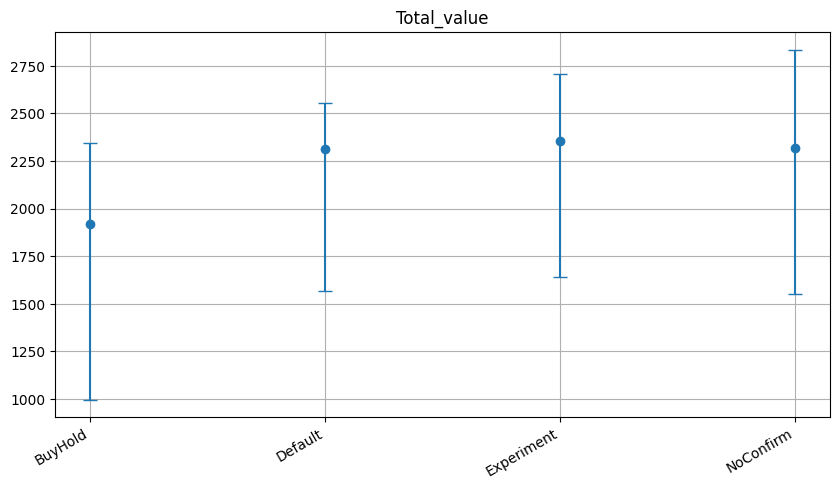

In [9]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

means = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    means.index,
    means.values,
    yerr=[means - low, high - means],
    fmt="o",
    capsize=5,
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()